**Studente:** Alessio Camerano  
**Matricola:** 1044444  
**Corso:** Analisi e Trattamento Segnali Digitali

---

### Indice dei Contenuti
- **1. Setup del Progetto**
  - 1.1. Importazione delle librerie
  - 1.2. Caricamento dei dati dal sensore
  - 1.3. Preprocessing del segnale (rimozione bias e media mobile)
- **2. Filtraggio del Segnale**
  - 2.1. Progettazione di un filtro IIR (Butterworth)
  - 2.2. Confronto visuale tra segnale grezzo, filtrato FIR e filtrato IIR
- **3. Analisi dei Filtri nel Piano Z**
  - 3.1. Diagramma poli-zeri del filtro FIR
  - 3.2. Diagramma poli-zeri del filtro IIR
- **4. Analisi nel Dominio del Tempo**
  - 4.1. Statistiche descrittive
  - 4.2. Visualizzazione dei segnali
  - 4.3. Analisi di auto-correlazione e cross-correlazione
- **5. Analisi nel Dominio della Frequenza**
  - 5.1. Stima della PSD con Periodogramma, Welch e modello AR
- **6. Analisi Tempo-Frequenza**
  - 6.1. Spettrogramma (STFT)
- **7. Conclusioni**
  - 7.1. Riepilogo dei risultati


# 1. Setup del Progetto

## 1.1. Importazione delle Librerie

In [26]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq
from pathlib import Path
from utils import load_gyro_data, get_sampling_frequency

# --- Stile e Parametri Globali ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 10

## 1.2. Caricamento dei Dati dal Sensore

In [27]:
DATA_DIR = Path('RawData')
exp_file = DATA_DIR / 'gyro_exp12_user06.txt'
data = load_gyro_data(exp_file)
fs = get_sampling_frequency()
T = 1 / fs
n_samples = len(data)
duration = n_samples * T
axis_names = ['gyro_x', 'gyro_y', 'gyro_z']
print(f"Dati caricati da '{exp_file.name}': {n_samples} campioni, durata {duration:.2f}s, fs={fs}Hz")

Dati caricati da 'gyro_exp12_user06.txt': 32089 campioni, durata 641.78s, fs=50.0Hz


## 1.3. Preprocessing del Segnale (Rimozione Bias e Media Mobile)

In [28]:
def moving_average(signal_data, window=5):
    """Filtro a media mobile per smussare il segnale."""
    return np.convolve(signal_data, np.ones(window)/window, mode='same')

def remove_bias(signal_data):
    """Rimuove la componente DC (media) dal segnale."""
    return signal_data - np.mean(signal_data)

# --- Applicazione Preprocessing ---
data_filt = pd.DataFrame({
    axis: remove_bias(moving_average(data[axis].values)) for axis in axis_names
})
print("✓ Preprocessing completato: filtro media mobile e rimozione bias applicati.")

✓ Preprocessing completato: filtro media mobile e rimozione bias applicati.


# 2. Filtraggio del Segnale
In questa sezione, confrontiamo il filtro a media mobile (FIR) con un filtro IIR più selettivo, come il **Butterworth**. L'obiettivo è mostrare il trade-off tra la semplicità del FIR e l'efficienza del IIR.
- **Filtro FIR (Media Mobile)**: Semplice e sempre stabile, ma meno efficace nel separare le frequenze.
- **Filtro IIR (Butterworth)**: Offre una transizione più netta tra banda passante e banda attenuata, ma richiede un'attenta progettazione per garantire la stabilità.

## 2.1. Progettazione di un Filtro IIR (Butterworth)

In [29]:
from scipy.signal import butter, lfilter

def butter_lowpass_filter(data, cutoff, fs, order=5):
    """Applica un filtro passa-basso Butterworth."""
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = lfilter(b, a, data)
    return y

# --- Applicazione Filtro IIR ---
cutoff_freq = 5  # Hz
data_iir = pd.DataFrame({
    axis: butter_lowpass_filter(data[axis].values, cutoff_freq, fs) for axis in axis_names
})
print(f"✓ Filtro IIR Butterworth applicato con frequenza di taglio a {cutoff_freq} Hz.")

✓ Filtro IIR Butterworth applicato con frequenza di taglio a 5 Hz.


## 2.2. Confronto Visuale tra Segnale Grezzo, Filtrato FIR e Filtrato IIR

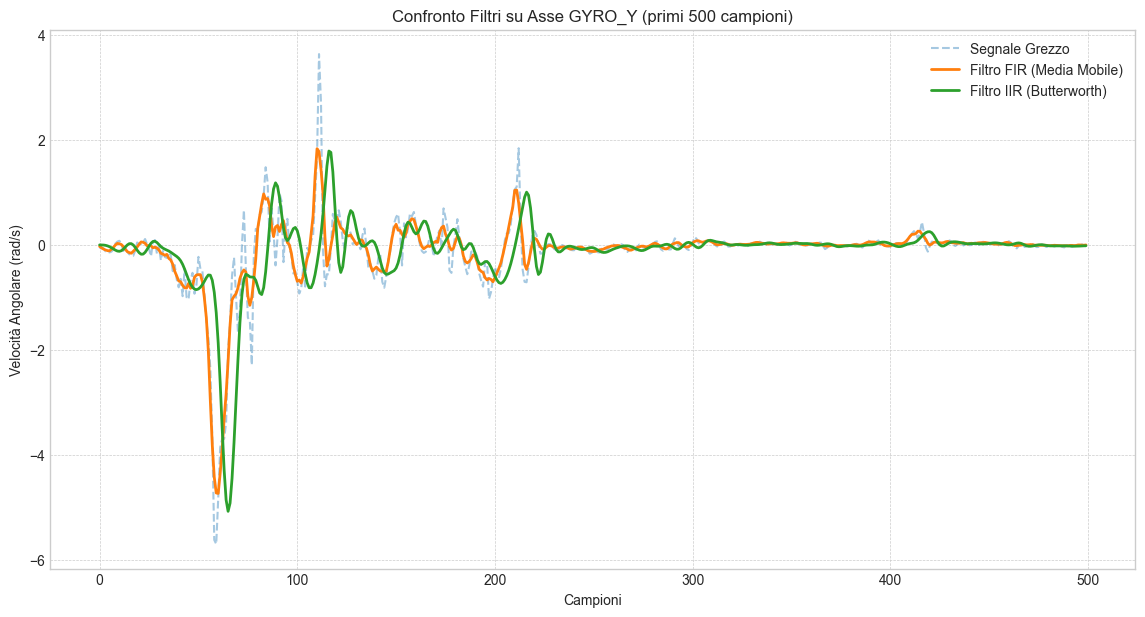

In [30]:
plt.figure(figsize=(14, 7))
axis_to_plot = 'gyro_y'
plt.plot(data[axis_to_plot].values[:500], label='Segnale Grezzo', alpha=0.4, linestyle='--')
plt.plot(data_filt[axis_to_plot].values[:500], label='Filtro FIR (Media Mobile)', linewidth=2)
plt.plot(data_iir[axis_to_plot].values[:500], label='Filtro IIR (Butterworth)', linewidth=2)
plt.title(f'Confronto Filtri su Asse {axis_to_plot.upper()} (primi 500 campioni)')
plt.xlabel('Campioni')
plt.ylabel('Velocità Angolare (rad/s)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

# 3. Analisi dei Filtri nel Piano Z
L'analisi dei poli e degli zeri di un filtro nel piano Z è cruciale per comprenderne il comportamento:
- **Stabilità**: Un filtro è stabile se tutti i suoi poli si trovano **all'interno del cerchio unitario**. I filtri FIR sono intrinsecamente stabili perché i loro poli sono sempre nell'origine.
- **Risposta in Frequenza**: La posizione degli **zeri** sul cerchio unitario indica le frequenze che il filtro sopprime completamente. La vicinanza dei **poli** al cerchio unitario, invece, amplifica le frequenze in quella regione.

## 3.1. Diagramma Poli-Zeri del Filtro FIR

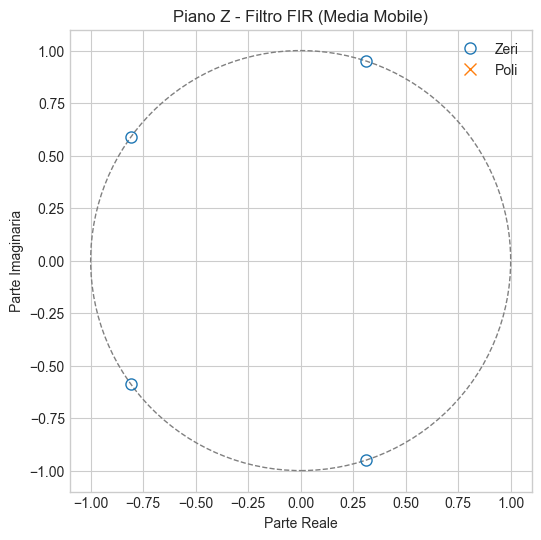

In [31]:
from scipy.signal import tf2zpk
import matplotlib.patches as mpatches

def plot_zplane(b, a, title="Diagramma Poli-Zeri"):
    """Visualizza il diagramma poli-zeri per un filtro nel piano Z."""
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Disegna il cerchio unitario
    unit_circle = mpatches.Circle((0, 0), 1, fill=False, color='gray', ls='--', lw=1)
    ax.add_patch(unit_circle)
    
    # Trova poli e zeri
    z, p, k = tf2zpk(b, a)
    
    # Plotta zeri (o) e poli (x)
    ax.plot(np.real(z), np.imag(z), 'o', markersize=8, fillstyle='none', label='Zeri')
    ax.plot(np.real(p), np.imag(p), 'x', markersize=8, label='Poli')
    
    ax.set_title(title)
    ax.set_xlabel('Parte Reale')
    ax.set_ylabel('Parte Imaginaria')
    ax.grid(True)
    ax.set_aspect('equal')
    ax.legend()
    plt.show()

# --- Diagramma per Filtro FIR (Media Mobile) ---
window_size = 5
b_fir = np.ones(window_size) / window_size
a_fir = np.array([1.0])
plot_zplane(b_fir, a_fir, title="Piano Z - Filtro FIR (Media Mobile)")

## 3.2. Diagramma Poli-Zeri del Filtro IIR

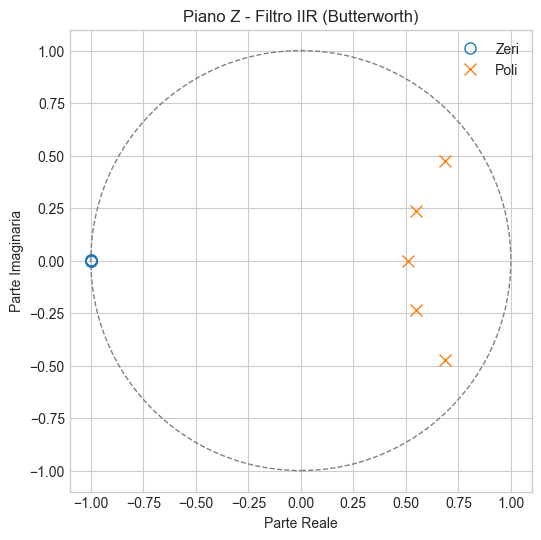

In [32]:
nyq = 0.5 * fs
normal_cutoff = cutoff_freq / nyq
b_iir, a_iir = butter(5, normal_cutoff, btype='low', analog=False)
plot_zplane(b_iir, a_iir, title="Piano Z - Filtro IIR (Butterworth)")

## 4.1. Statistiche Descrittive

In [33]:
print("\n--- Analisi Statistica Confrontata ---")
stats = pd.DataFrame({
    'Media Grezzo': data[axis_names].mean(),
    'Media Filtrato': data_filt[axis_names].mean(),
    'Std Dev Grezzo': data[axis_names].std(),
    'Std Dev Filtrato': data_filt[axis_names].std()
})
print(stats)


--- Analisi Statistica Confrontata ---
        Media Grezzo  Media Filtrato  Std Dev Grezzo  Std Dev Filtrato
gyro_x      0.040420    0.000000e+00        0.647423          0.557286
gyro_y     -0.007699    0.000000e+00        0.673691          0.533480
gyro_z     -0.010118    6.642863e-18        0.540248          0.443787


## 4.2. Visualizzazione dei Segnali

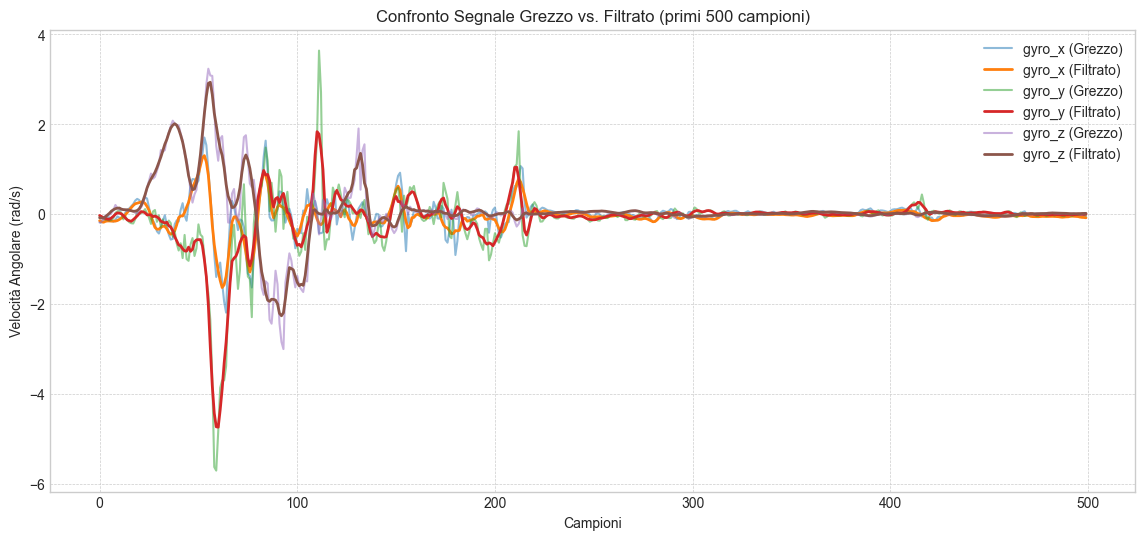

In [34]:
plt.figure(figsize=(14, 6))
for axis in axis_names:
    plt.plot(data[axis].values[:500], label=f'{axis} (Grezzo)', alpha=0.5)
    plt.plot(data_filt[axis].values[:500], label=f'{axis} (Filtrato)', linewidth=2)
plt.title('Confronto Segnale Grezzo vs. Filtrato (primi 500 campioni)')
plt.xlabel('Campioni')
plt.ylabel('Velocità Angolare (rad/s)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

## 4.3. Analisi di Auto-correlazione e Cross-correlazione

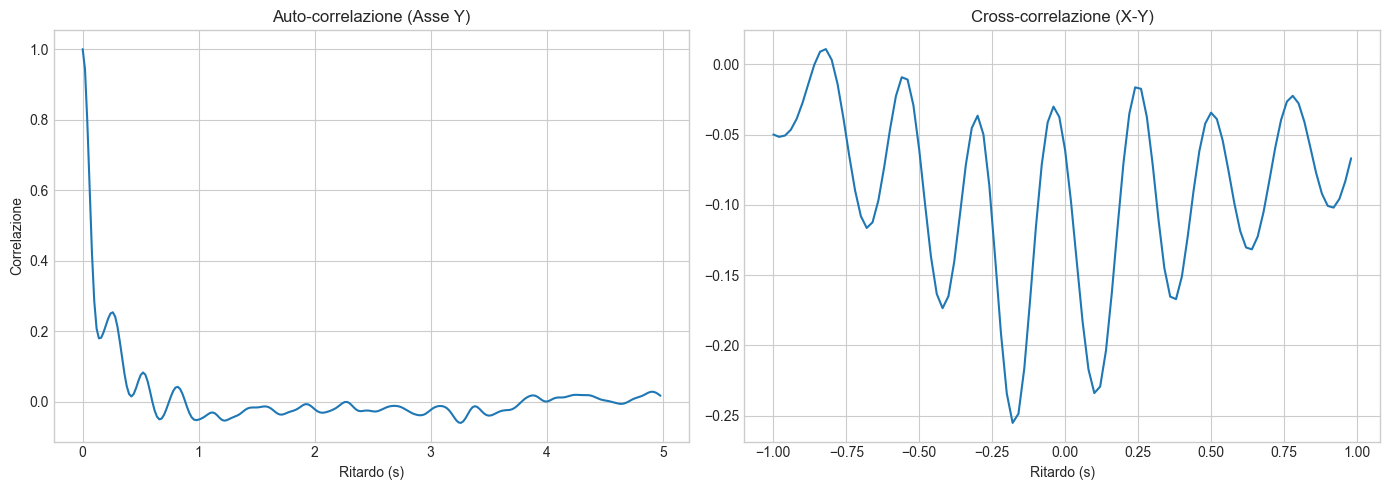

In [35]:
def compute_autocorr(x, max_lag):
    """Calcola l'auto-correlazione normalizzata."""
    x_norm = (x - np.mean(x)) / np.std(x)
    ac = np.correlate(x_norm, x_norm, mode='full')
    mid = len(ac) // 2
    return ac[mid:mid + max_lag] / ac[mid]

def compute_crosscorr(x, y, max_lag):
    """Calcola la cross-correlazione normalizzata."""
    x_norm = (x - np.mean(x)) / np.std(x)
    y_norm = (y - np.mean(y)) / np.std(y)
    cc = np.correlate(x_norm, y_norm, mode='full')
    mid = len(cc) // 2
    return cc[mid - max_lag:mid + max_lag] / len(x)

# --- Auto-correlazione e Cross-correlazione ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
max_lag_ac = 250
max_lag_cc = 50

# Auto-correlazione
lags_ac = np.arange(max_lag_ac) * T
ac = compute_autocorr(data_filt['gyro_y'].values, max_lag_ac)
axes[0].plot(lags_ac, ac)
axes[0].set_title('Auto-correlazione (Asse Y)')
axes[0].set_xlabel('Ritardo (s)')
axes[0].set_ylabel('Correlazione')
axes[0].grid(True)

# Cross-correlazione
lags_cc = np.arange(-max_lag_cc, max_lag_cc) * T
cc = compute_crosscorr(data_filt['gyro_x'].values, data_filt['gyro_y'].values, max_lag_cc)
axes[1].plot(lags_cc, cc)
axes[1].set_title('Cross-correlazione (X-Y)')
axes[1].set_xlabel('Ritardo (s)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 5. Analisi nel Dominio della Frequenza

## 5.1. Stima della PSD con Periodogramma, Welch e Modello AR

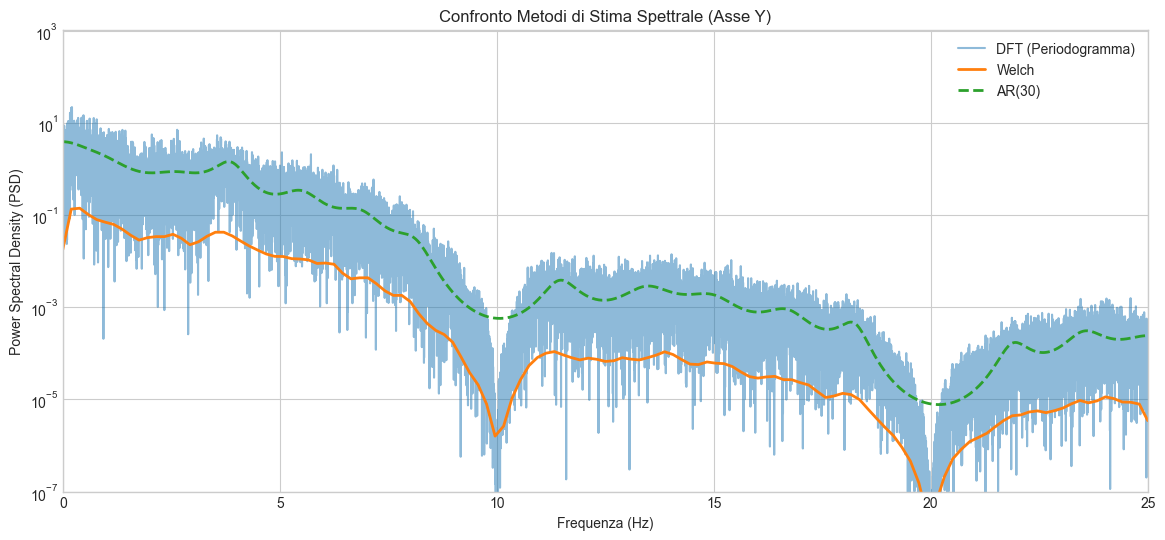

In [36]:
from scipy.signal import welch
from statsmodels.regression.linear_model import yule_walker

# --- Funzioni per Stima Spettrale ---
def compute_power_spectrum(signal_data, fs):
    """Calcola lo spettro di potenza tramite DFT."""
    N = len(signal_data)
    fft_vals = fft(signal_data)
    freqs = fftfreq(N, 1/fs)
    mask = freqs >= 0
    power = (np.abs(fft_vals[mask])**2) / N # PSD
    return freqs[mask], power

def ar_psd(x, order, fs):
    """Stima la PSD con un modello AR(p) via equazioni di Yule-Walker."""
    rho, sigma = yule_walker(x, order)
    # Calcola la risposta in frequenza del filtro AR
    freqs, h = signal.freqz(1, np.r_[1, -rho], worN=1024, fs=fs)
    # Calcola la PSD
    psd = sigma**2 * np.abs(h)**2
    return freqs, psd

# --- Calcolo e Confronto ---
signal_to_analyze = data_filt['gyro_y'].values
plt.figure(figsize=(14, 6))

# 1. DFT (Periodogramma)
f_dft, p_dft = compute_power_spectrum(signal_to_analyze, fs)
plt.semilogy(f_dft, p_dft, label='DFT (Periodogramma)', alpha=0.5)

# 2. Welch
f_welch, p_welch = welch(signal_to_analyze, fs=fs, nperseg=256)
plt.semilogy(f_welch, p_welch, label='Welch', linewidth=2)

# 3. AR
f_ar, p_ar = ar_psd(signal_to_analyze, order=30, fs=fs)
plt.semilogy(f_ar, p_ar, label='AR(30)', linewidth=2, linestyle='--')

# --- Grafico ---
plt.title('Confronto Metodi di Stima Spettrale (Asse Y)')
plt.xlabel('Frequenza (Hz)')
plt.ylabel('Power Spectral Density (PSD)')
plt.xlim(0, fs / 2)
plt.ylim(bottom=1e-7)
plt.legend()
plt.grid(True, which='both')
plt.show()

# 6. Analisi Tempo-Frequenza

## 6.1. Spettrogramma (STFT)
Lo spettrogramma mostra come il contenuto in frequenza del segnale cambia nel tempo. È utile per analizzare segnali non stazionari.

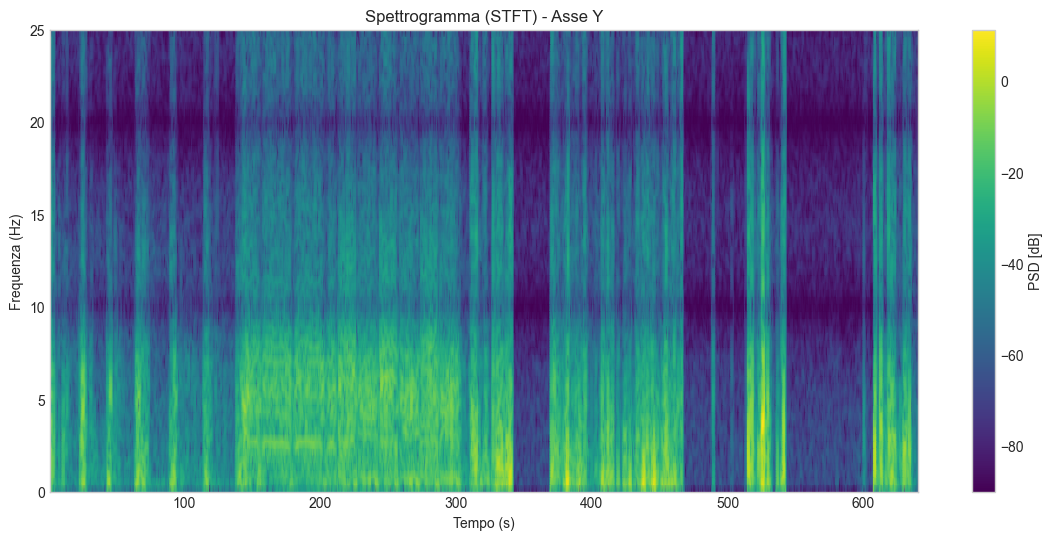

In [37]:
from scipy.signal import spectrogram

# --- Calcolo STFT ---
f_stft, t_stft, Sxx = spectrogram(data_filt['gyro_y'].values, fs=fs, nperseg=128, noverlap=96)

# --- Visualizzazione ---
plt.figure(figsize=(14, 6))
plt.pcolormesh(t_stft, f_stft, 10 * np.log10(Sxx + 1e-9), shading='gouraud', cmap='viridis')
plt.colorbar(label='PSD [dB]')
plt.title('Spettrogramma (STFT) - Asse Y')
plt.ylabel('Frequenza (Hz)')
plt.xlabel('Tempo (s)')
plt.ylim(0, fs / 2)
plt.show()

# 7. Conclusioni

## 7.1. Riepilogo dei Risultati
Questo progetto ha mostrato un flusso di lavoro completo per l'analisi di segnali giroscopici:
- **Pulizia del segnale**: Il preprocessing si è rivelato fondamentale per rimuovere il rumore e le componenti DC.
- **Analisi Temporale**: L'auto-correlazione ha identificato la periodicità del movimento, mentre la cross-correlazione ha mostrato la sincronia tra gli assi.
- **Analisi Spettrale**: Il metodo di Welch si è dimostrato un ottimo compromesso tra riduzione della varianza e risoluzione in frequenza, superiore al semplice periodogramma. Il modello AR offre una visione parametrica e liscia dello spettro.
- **Analisi Tempo-Frequenza**: Lo spettrogramma ha confermato la stabilità delle componenti frequenziali nel tempo, caratteristica di un movimento periodico.